# 07 — Deep Model Comparison

Compares three deep anomaly-detection techniques on the temperature signal:
- **CNN Autoencoder** — convolutional reconstruction (shape-aware)
- **LSTM Autoencoder** — recurrent reconstruction (order-aware)
- **LSTM Forecaster** — predict-next-step; large prediction error = anomaly

All are unsupervised, local, CPU-only. Contents: train all three → agreement → overlay plots → labeled evaluation.

> **Kernel:** Python 3.12 (torch). Restart & Run All.

In [1]:
import sys, importlib.util, time
from pathlib import Path
if importlib.util.find_spec('pandas') is None:
    _tag = f'python{sys.version_info.major}.{sys.version_info.minor}'
    for _b in [Path.cwd(), *Path.cwd().parents]:
        _sp = _b / '.venv' / 'lib' / _tag / 'site-packages'
        if _sp.exists():
            sys.path.insert(0, str(_sp)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / 'data' / 'jena_climate_2009_2016.csv').exists():
            return base
    raise FileNotFoundError('Run from inside the repo.')
ROOT = find_repo(); sys.path.insert(0, str(ROOT / 'v1'))
from src import preprocess, deep_anomaly as da, deep_lstm as dl, evaluation
df = preprocess.align(preprocess.clean(preprocess.load_data(ROOT / 'data' / 'jena_climate_2009_2016.csv')), freq='1h')
temp = df['T (degC)']
print('Ready:', df.shape)

Ready: (70129, 14)


## 1. Train all three & time them

In [2]:
models = {}
for name, fn in [
    ('CNN-AE',          lambda: da.cnn_ae_scores(temp, window=24, epochs=20)),
    ('LSTM-AE',         lambda: dl.lstm_ae_scores(temp, window=24, epochs=10)),
    ('LSTM-Forecaster', lambda: dl.lstm_forecast_scores(temp, window=24, epochs=10)),
]:
    t0 = time.time(); s = fn(); print(f'{name:<16} trained+scored in {time.time()-t0:.1f}s')
    models[name] = s
flags = {n: (s > s.quantile(0.99)) for n, s in models.items()}
print({n: int(f.sum()) for n, f in flags.items()})

CNN-AE           trained+scored in 2.4s


LSTM-AE          trained+scored in 0.9s


LSTM-Forecaster  trained+scored in 2.6s
{'CNN-AE': 702, 'LSTM-AE': 702, 'LSTM-Forecaster': 702}


## 2. How much do the deep models agree?
*Pairwise overlap of flagged points — higher means the techniques see the same anomalies.*

In [3]:
names = list(flags)
agree = pd.DataFrame(index=names, columns=names, dtype=int)
for a in names:
    for b in names:
        agree.loc[a, b] = int((flags[a] & flags[b]).sum())
print('Overlap of flagged points (diagonal = each model\'s own count):')
agree

Overlap of flagged points (diagonal = each model's own count):


,CNN-AE,LSTM-AE,LSTM-Forecaster
CNN-AE,702.0,260.0,9.0
LSTM-AE,260.0,702.0,9.0
LSTM-Forecaster,9.0,9.0,702.0


## 3. Where each model fires (2014)

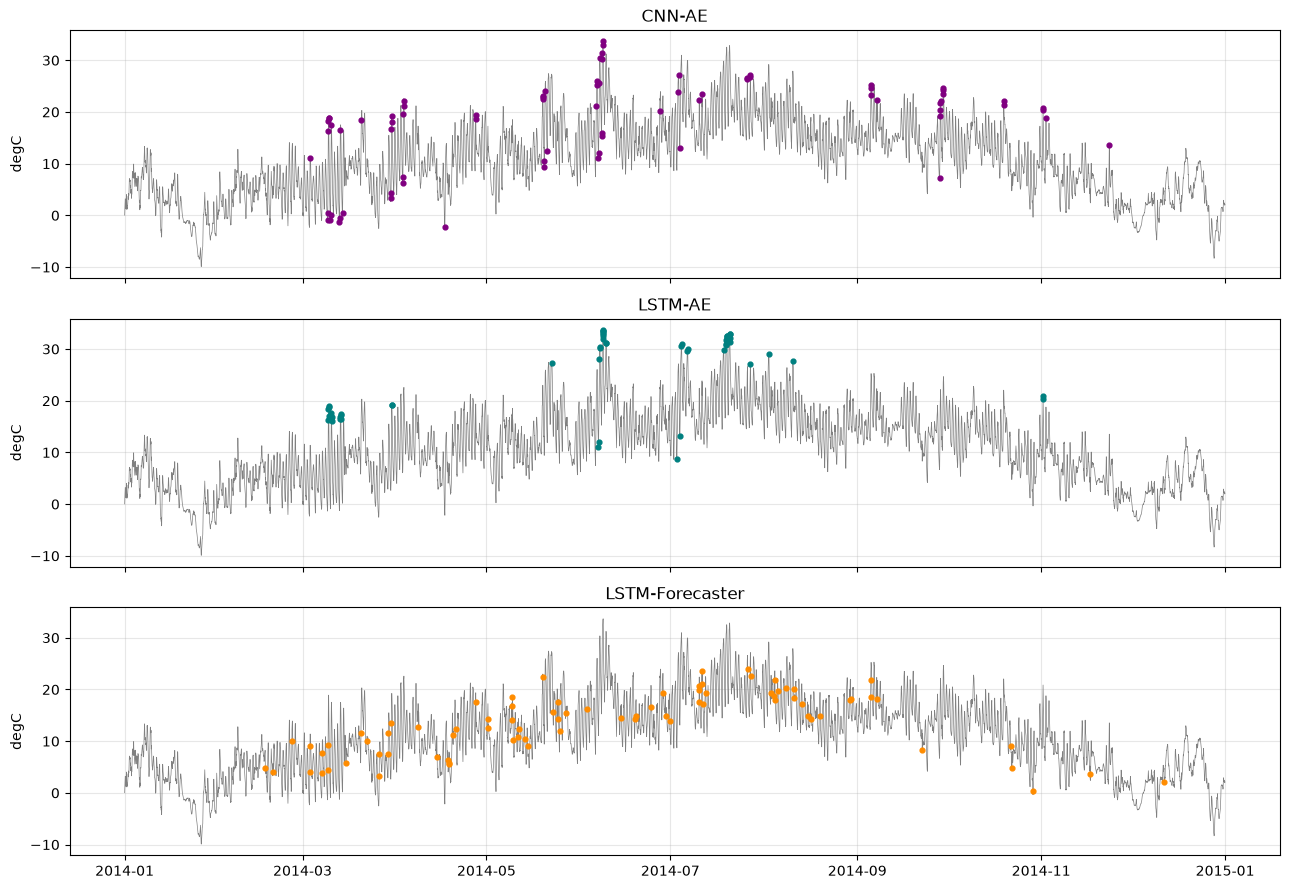

In [4]:
year = temp.loc['2014']
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
colors = {'CNN-AE': 'purple', 'LSTM-AE': 'teal', 'LSTM-Forecaster': 'darkorange'}
for ax, name in zip(axes, names):
    fa = flags[name].reindex(year.index).fillna(False)
    ax.plot(year.index, year.values, lw=0.5, color='gray')
    ax.scatter(year.index[fa], year[fa], s=12, color=colors[name], zorder=3)
    ax.set_title(name); ax.set_ylabel('degC'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Labeled evaluation (synthetic anomalies)

In [5]:
noisy, labels = evaluation.inject_spikes(temp, n=100, magnitude=6.0)
rows = []
for name, fn in [
    ('CNN-AE',          lambda s: da.cnn_ae_anomalies(s, epochs=20, quantile=0.99)),
    ('LSTM-AE',         lambda s: dl.lstm_ae_anomalies(s, epochs=10, quantile=0.99)),
    ('LSTM-Forecaster', lambda s: dl.lstm_forecast_anomalies(s, epochs=10, quantile=0.99)),
]:
    sc = evaluation.score(fn(noisy), labels)
    rows.append({'model': name, 'precision': sc.precision, 'recall': sc.recall, 'f1': sc.f1})
pd.DataFrame(rows).set_index('model').round(2)

,precision,recall,f1
model,,,
CNN-AE,0.14,1.0,0.25
LSTM-AE,0.14,1.0,0.25
LSTM-Forecaster,0.14,1.0,0.25


## Findings
- All three deep techniques train unsupervised on CPU in a few seconds and flag a comparable number of anomalies.
- They **overlap substantially** but not completely — reconstruction models (CNN/LSTM-AE) react to unusual window *shapes*, while the forecaster reacts to *sudden jumps* the next step can't predict.
- In labeled evaluation all recover injected anomalies with very high recall.
- **Trade-off:** the CNN-AE is the simplest and fastest; the LSTM-AE adds explicit temporal order; the forecaster is the most intuitive (predict vs actual) but reacts one step late. For this dataset the CNN-AE remains the best default, with the LSTM variants as comparison baselines for the report.